In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/model_clean.csv")
y = "market_value_in_eur"

train, temp = train_test_split(df, test_size=0.30, random_state=42)
val, test = train_test_split(temp, test_size=0.50, random_state=42)

print("Trening:", len(train), " Validering:", len(val), " Test:", len(test))

Trening: 3773  Validering: 809  Test: 809


In [2]:
def evaluer(navn, y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    rel = np.abs(y_pred - y_true) / y_true
    return {
        "modell": navn,
        "median_rel_feil": np.median(rel),
        "MAE_mill_eur": np.mean(np.abs(y_pred - y_true)) / 1e6,
    }

resultater = []

In [3]:
tabell = train.groupby(["league", "position"])[y].median().to_dict()
liga_median = train.groupby("league")[y].median().to_dict()
total_median = train[y].median()

def baseline_predict(data):
    return [
        tabell.get((l, p), liga_median.get(l, total_median))
        for l, p in zip(data["league"], data["position"])
    ]

pd.Series(tabell).unstack().round(-3)

,Attack,Defender,Goalkeeper,Midfield
BE1,2500000.0,2000000.0,900000.0,2350000.0
DK1,1200000.0,1200000.0,675000.0,800000.0
ES1,5000000.0,4000000.0,2900000.0,5000000.0
FR1,7000000.0,6000000.0,2500000.0,8000000.0
GB1,28000000.0,18000000.0,10000000.0,25000000.0
GR1,700000.0,500000.0,700000.0,850000.0
IT1,9000000.0,6000000.0,3250000.0,7000000.0
L1,8000000.0,5500000.0,4000000.0,8000000.0
NL1,1500000.0,1500000.0,2000000.0,1250000.0
PO1,1500000.0,1200000.0,1100000.0,2000000.0


In [4]:
pred_val = baseline_predict(val)
resultater.append(evaluer("Baseline (median liga × posisjon)", val[y], pred_val))

pd.DataFrame(resultater)

,modell,median_rel_feil,MAE_mill_eur
0,Baseline (median liga × posisjon),0.7,5.785878


In [5]:
kategorier = ["position", "sub_position", "foot", "league"]
numeriske = [
    "age", "height_in_cm", "contract_years_left", "contract_missing",
    "games", "minutes", "goals", "assists", "yellow",
    "goals_per90", "assists_per90", "cl_minutes",
    "international_caps", "international_goals",
]

X_train, y_train = train[kategorier + numeriske], train[y]
X_val, y_val = val[kategorier + numeriske], val[y]
X_test, y_test = test[kategorier + numeriske], test[y]

In [6]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeriske),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), kategorier),
])

def lag_modell(regressor):
    pipe = Pipeline([("prep", preprocess), ("model", regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

In [7]:
modeller = {
    "Ridge": lag_modell(Ridge(alpha=1.0)),
    "Random Forest": lag_modell(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)),
    "HistGradientBoosting": lag_modell(HistGradientBoostingRegressor(random_state=42)),
}

for navn, modell in modeller.items():
    modell.fit(X_train, y_train)
    resultater.append(evaluer(navn, y_val, modell.predict(X_val)))
    print("Ferdig:", navn)

resultattabell = pd.DataFrame(resultater).sort_values("median_rel_feil")
resultattabell

Ferdig: Ridge
Ferdig: Random Forest
Ferdig: HistGradientBoosting


,modell,median_rel_feil,MAE_mill_eur
3,HistGradientBoosting,0.418417,3.347492
2,Random Forest,0.476159,3.823135
1,Ridge,0.480727,5.531776
0,Baseline (median liga × posisjon),0.700000,5.785878


In [8]:
beste_navn = resultattabell[resultattabell["modell"] != "Baseline (median liga × posisjon)"].iloc[0]["modell"]
beste = modeller[beste_navn]

test_resultat = pd.DataFrame([
    evaluer("Baseline (test)", y_test, baseline_predict(test)),
    evaluer(f"{beste_navn} (test)", y_test, beste.predict(X_test)),
])
test_resultat

,modell,median_rel_feil,MAE_mill_eur
0,Baseline (test),0.700000,5.958220
1,HistGradientBoosting (test),0.421606,3.453338


In [9]:
import matplotlib.pyplot as plt

analyse = pd.concat([val, test]).copy()
analyse["pred"] = beste.predict(analyse[kategorier + numeriske])
analyse["rel_feil"] = (analyse["pred"] - analyse[y]).abs() / analyse[y]
analyse["ratio"] = analyse["pred"] / analyse[y]
print(len(analyse), "spillere i analysen")

1618 spillere i analysen


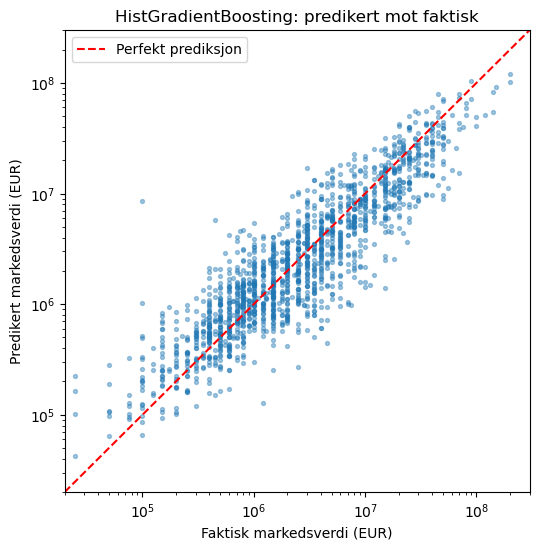

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(analyse[y], analyse["pred"], s=8, alpha=0.4)
grenser = [2e4, 3e8]
ax.plot(grenser, grenser, "r--", label="Perfekt prediksjon")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(grenser)
ax.set_ylim(grenser)
ax.set_xlabel("Faktisk markedsverdi (EUR)")
ax.set_ylabel("Predikert markedsverdi (EUR)")
ax.set_title(f"{beste_navn}: predikert mot faktisk")
ax.legend()
plt.show()

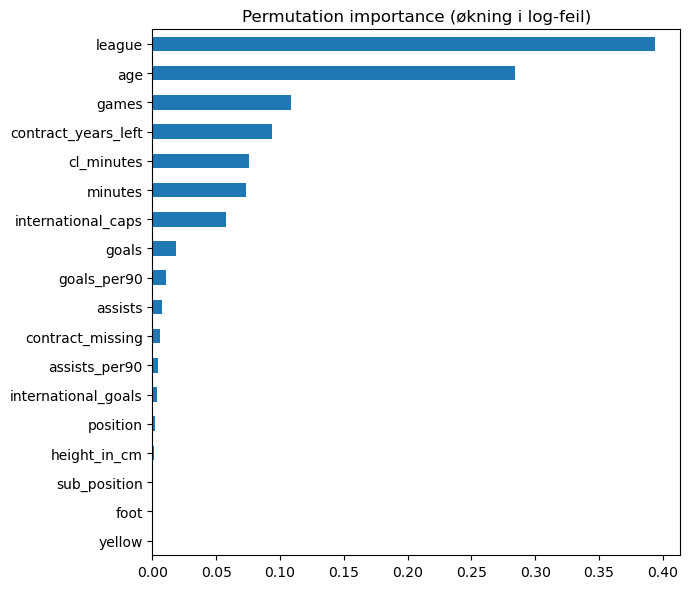

league                 0.393705
age                    0.283759
games                  0.108422
contract_years_left    0.093539
cl_minutes             0.075909
minutes                0.073467
international_caps     0.057995
goals                  0.018576
goals_per90            0.010880
assists                0.007133
contract_missing       0.006137
assists_per90          0.003987
international_goals    0.003279
position               0.002266
height_in_cm           0.000876
sub_position           0.000303
foot                   0.000229
yellow                 0.000041
dtype: float64

In [11]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer

def neg_log_mae(y_true, y_pred):
    return -np.mean(np.abs(np.log1p(y_pred) - np.log1p(y_true)))

pi = permutation_importance(
    beste, analyse[kategorier + numeriske], analyse[y],
    scoring=make_scorer(neg_log_mae), n_repeats=10, random_state=42, n_jobs=-1,
)

viktighet = pd.Series(pi.importances_mean, index=kategorier + numeriske).sort_values()
viktighet.plot.barh(figsize=(7, 6), title="Permutation importance (økning i log-feil)")
plt.tight_layout()
plt.show()
viktighet.sort_values(ascending=False)

In [12]:
analyse["aldersgruppe"] = pd.cut(analyse["age"], bins=[15, 21, 24, 27, 30, 33, 45],
                                 labels=["≤21", "22–24", "25–27", "28–30", "31–33", "34+"])

per_alder = analyse.groupby("aldersgruppe", observed=True)["rel_feil"].agg(["median", "count"])
per_liga = analyse.groupby("league")["rel_feil"].agg(["median", "count"]).sort_values("median")

print("Median relativ feil per aldersgruppe")
display(per_alder.round(3))
print("Median relativ feil per liga")
display(per_liga.round(3))

Median relativ feil per aldersgruppe


,median,count
aldersgruppe,,
≤21,0.496,107
22–24,0.452,324
25–27,0.431,429
28–30,0.407,343
31–33,0.357,230
34+,0.419,185


Median relativ feil per liga


,median,count
league,,
ES1,0.324,135
GB1,0.326,144
L1,0.382,93
IT1,0.384,123
UKR1,0.385,87
FR1,0.406,127
TR1,0.414,105
GR1,0.423,97
SC1,0.435,90


In [13]:
topp = analyse.sort_values("ratio", ascending=False).head(15)

visning = topp[["name", "age", "position", "league", "minutes", "goals", "assists", "cl_minutes"]].copy()
visning["faktisk_mill"] = (topp[y] / 1e6).round(2)
visning["predikert_mill"] = (topp["pred"] / 1e6).round(2)
visning["ratio"] = topp["ratio"].round(1)
visning["age"] = visning["age"].round(1)
visning

,name,age,position,league,minutes,goals,assists,cl_minutes,faktisk_mill,predikert_mill,ratio
5293,Benjamin Arthur,20.7,Defender,GB1,607,0,0,0.0,0.10,8.57,85.7
4507,Milan Zonneveld,22.7,Attack,NL1,1319,11,4,0.0,0.45,5.80,12.9
199,Hallur Hansson,34.0,Midfield,annet,511,0,0,0.0,0.10,1.03,10.3
4537,Ivan Mamrosenko,26.3,Defender,UKR1,634,0,0,0.0,0.02,0.22,9.0
1095,Sander Svendsen,28.9,Attack,TR1,674,6,0,0.0,0.60,4.26,7.1
218,Jannich Storch,33.1,Goalkeeper,DK1,660,0,0,0.0,0.02,0.17,6.6
4065,Tyrese Noslin,23.8,Midfield,NL1,2645,3,4,0.0,0.75,4.57,6.1
2900,Júnior Brumado,27.1,Attack,DK1,1992,16,2,0.0,0.80,4.72,5.9
1174,Luke O'Nien,31.6,Defender,GB1,864,0,1,0.0,0.70,4.08,5.8
3611,Raúl García,25.7,Attack,ES1,1384,14,2,0.0,3.00,17.11,5.7


In [14]:
kandidater = analyse[(analyse[y] >= 500_000) & (analyse["minutes"] >= 900)]
topp = kandidater.sort_values("ratio", ascending=False).head(15)

visning = topp[["name", "age", "position", "league", "minutes", "goals", "assists", "cl_minutes"]].copy()
visning["faktisk_mill"] = (topp[y] / 1e6).round(2)
visning["predikert_mill"] = (topp["pred"] / 1e6).round(2)
visning["ratio"] = topp["ratio"].round(1)
visning["age"] = visning["age"].round(1)
print(len(kandidater), "kandidater etter filter")
visning

1122 kandidater etter filter


,name,age,position,league,minutes,goals,assists,cl_minutes,faktisk_mill,predikert_mill,ratio
4065,Tyrese Noslin,23.8,Midfield,NL1,2645,3,4,0.0,0.75,4.57,6.1
2900,Júnior Brumado,27.1,Attack,DK1,1992,16,2,0.0,0.80,4.72,5.9
3611,Raúl García,25.7,Attack,ES1,1384,14,2,0.0,3.00,17.11,5.7
3615,Bruno Langa,28.7,Defender,PO1,1048,0,0,102.0,1.00,5.40,5.4
4299,Valdemar Byskov,21.4,Midfield,DK1,1630,7,4,0.0,2.20,9.50,4.3
5361,Yaroslav Shevchenko,19.8,Midfield,UKR1,1339,4,1,0.0,0.70,2.99,4.3
122,Martin Dúbravka,37.5,Goalkeeper,GB1,3150,0,0,0.0,0.50,2.07,4.1
4183,Danilo Veiga,23.8,Defender,IT1,3145,0,1,0.0,2.50,10.31,4.1
3914,Dailon Livramento,25.2,Attack,IT1,1089,0,1,0.0,0.80,3.17,4.0
4967,Dermane Karim,22.5,Midfield,FR1,1361,1,2,0.0,2.50,9.83,3.9


In [15]:
visning["kontrakt_år"] = topp["contract_years_left"].round(1)